## Ticket Classification

### Load dataset

 Hugging Face Dataset - https://huggingface.co/datasets/mteb/banking77

In [1]:
# import libraries

from datasets import load_dataset, DatasetDict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from transformers import pipeline
from transformers import AutoTokenizer
from transformers import TrainingArguments, Trainer
from transformers import AutoModelForSequenceClassification, DistilBertForSequenceClassification, DistilBertModel

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import f1_score

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

In [2]:
bank_df = load_dataset("mteb/banking77")
bank_df

README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/294k [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/91.4k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/9993 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3076 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 9993
    })
    test: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 3076
    })
})

In [3]:
test_df = bank_df["test"].to_pandas()
train_df = bank_df["train"].to_pandas()

train_df.head()

,text,label,label_text
0,I am still waiting on my card?,11,card_arrival
1,What can I do if my card still hasn't arrived ...,11,card_arrival
2,I have been waiting over a week. Is the card s...,11,card_arrival
3,Can I track my card while it is in the process...,11,card_arrival
4,"How do I know if I will get my card, or if it ...",11,card_arrival


### Exploratory Analysis

In [4]:
# check duplicate
train_df["text"].duplicated().sum()

np.int64(0)

In [5]:
# data info
train_df["label"].value_counts().describe()

count     77.000000
mean     129.779221
std       32.974321
min       35.000000
25%      111.000000
50%      127.000000
75%      158.000000
max      187.000000
Name: count, dtype: float64

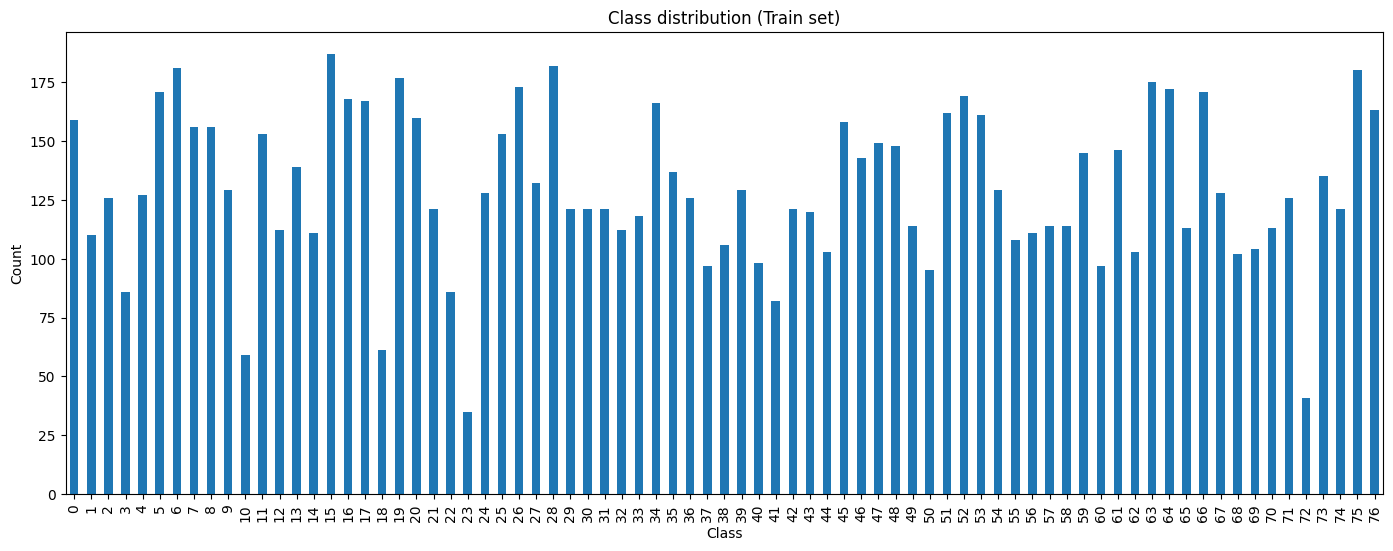

In [6]:
# class distribution
train_df["label"].value_counts().sort_index().plot(kind="bar", figsize=(17,6))
plt.title("Class distribution (Train set)")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

In [7]:
# words check
for label in sorted(train_df["label"].unique())[:5]:
    print(f"\nClass {label}")
    print(train_df[train_df["label"] == label]["text"].sample(5).values)


Class 0
['Can I get some help activating my new card?'
 'What is the most efficient way to activate my new card?'
 'I would like to be assisted with the activation of my card.'
 'My card needs to be activated asap'
 "I tried activating my card and it doesn't work how do I solve this problem?"]

Class 1
['How old do kids have to be to open an account?'
 'I want to open an account for my children'
 "I'd like to open an account for my kids can I do that?"
 'How old do you need to be to have an account?'
 'At what age can I open an account?']

Class 2
['How do I top up using my Apple Watch?'
 "Google Pay isn't working. What is wrong?"
 'How do you Top Up on the apple watch?'
 'Can I add funds directly from my Apple Watch?'
 'Does google play offer the service to Top up?']

Class 3
['need to know places i can withdraw money'
 'I need help from someone in your department with finding my nearest ATM.'
 'What locations allow me to withdraw money?'
 'Can I withdraw from any ATM?' 'Where can I 

In [8]:
# text length analysis
train_df["text_length"] = train_df["text"].apply(lambda x: len(x.split()))
train_df["text_length"].describe()

count    9993.000000
mean       11.955369
std         7.891187
min         3.000000
25%         7.000000
50%        10.000000
75%        13.000000
max        79.000000
Name: text_length, dtype: float64

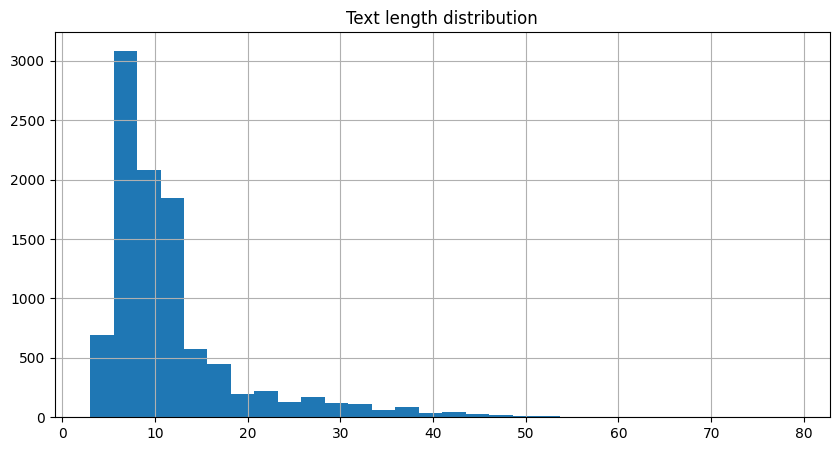

In [9]:
train_df["text_length"].hist(bins=30, figsize=(10,5))
plt.title("Text length distribution")
plt.show()

In [10]:
# outliers
train_df.sort_values("text_length", ascending=False).head(10)

,text,label,label_text,text_length
3914,Hearing back from us regarding your important ...,68,unable_to_verify_identity,79
7301,Hi! I'm a university student studying abroad a...,64,transfer_fee_charged,78
3931,Hearing about your verification results from u...,68,unable_to_verify_identity,75
3902,You will hear back from us about your verifica...,68,unable_to_verify_identity,70
3907,It can take between 10 minutes to an hour befo...,68,unable_to_verify_identity,70
5508,Hello-Can you please help me get a refund from...,52,request_refund,69
7220,"I transferred 7,000 to a receiver outside the ...",64,transfer_fee_charged,68
6384,My account shows I have been charged twice for...,63,transaction_charged_twice,66
3634,I think my card is being used by someone else ...,16,card_payment_not_recognised,64
3929,"If you are waiting for verification, it can ta...",68,unable_to_verify_identity,64


In [11]:
# long text
long_texts = train_df[train_df["text"].apply(lambda x: len(x.split()) > 40)]
print(long_texts["label"].value_counts())

label
63    19
64    19
66    16
46    12
51    11
28     7
35     7
75     6
53     6
68     5
48     5
52     4
19     3
16     3
15     3
25     2
22     2
41     1
6      1
47     1
8      1
42     1
27     1
7      1
59     1
5      1
Name: count, dtype: int64


In [12]:
#
words = " ".join(train_df["text"]).lower().split()
Counter(words).most_common(20)

[('i', 8305),
 ('my', 5682),
 ('to', 4006),
 ('a', 3564),
 ('the', 3496),
 ('is', 2338),
 ('can', 1837),
 ('do', 1729),
 ('card', 1635),
 ('it', 1556),
 ('for', 1534),
 ('how', 1511),
 ('what', 1367),
 ('why', 1233),
 ('and', 1212),
 ('you', 1177),
 ('was', 1089),
 ('have', 975),
 ('not', 953),
 ('in', 944)]

In [13]:
# exclude stop words
filtered_words = [w for w in words if w not in ENGLISH_STOP_WORDS]
Counter(filtered_words).most_common(20)

[('card', 1635),
 ('money', 919),
 ('transfer', 860),
 ('need', 695),
 ('account', 684),
 ('card?', 653),
 ('payment', 644),
 ('cash', 578),
 ('exchange', 504),
 ('charged', 501),
 ('use', 409),
 ('did', 379),
 ('fee', 372),
 ('long', 343),
 ('atm', 338),
 ('new', 334),
 ('account?', 324),
 ("didn't", 308),
 ('does', 303),
 ("don't", 303)]

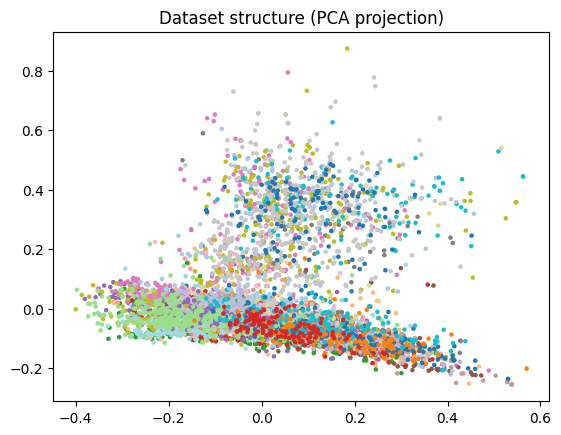

In [14]:
# PCA
vec = TfidfVectorizer(max_features=500)
X = vec.fit_transform(train_df["text"])

X_reduced = PCA(n_components=2).fit_transform(X.toarray())

plt.scatter(X_reduced[:,0], X_reduced[:,1], c=train_df["label"], cmap="tab20", s=5)
plt.title("Dataset structure (PCA projection)")
plt.show()

### Tokenization

In [15]:
# load tokenizer
name = "distilbert/distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(name)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [16]:
# Prepare the dataset - this tokenizes the dataset in batches of 16 examples.
bank_tokenized = bank_df.map(
    lambda example: tokenizer(example['text'], 
                              padding=True, 
                              truncation=True, 
                              max_length=64), 
    batched=True, batch_size=16
)

bank_tokenized = bank_tokenized.remove_columns(["text", "label_text"])
bank_tokenized = bank_tokenized.rename_column("label", "labels")
bank_tokenized.set_format("torch")

Map:   0%|          | 0/9993 [00:00<?, ? examples/s]

Map:   0%|          | 0/3076 [00:00<?, ? examples/s]

In [17]:
bank_tokenized['train'][0:2]

{'labels': tensor([11, 11]),
 'input_ids': tensor([[ 101, 1045, 2572, 2145, 3403, 2006, 2026, 4003, 1029,  102,    0,    0,
             0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0],
         [ 101, 2054, 2064, 1045, 2079, 2065, 2026, 4003, 2145, 8440, 1005, 1056,
          3369, 2044, 1016, 3134, 1029,  102,    0,    0,    0,    0,    0]]),
 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]),
 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0]])}

### Fine-tune with HuggingFace Trainer

In [18]:
model = DistilBertForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=77)

arguments = TrainingArguments(
    output_dir="banking77_trainer",
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=8,
    eval_strategy="epoch", # run validation at the end of each epoch
    save_strategy="epoch",
    weight_decay=0.01,
    learning_rate=2e-5,
    load_best_model_at_end=True,
    seed=224
)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [19]:
def compute_metrics(eval_pred):
    """Called at the end of validation. Gives accuracy"""
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    
    # calculates the accuracy and f1-score
    acc = np.mean(predictions == labels)
    f1 = f1_score(labels, predictions, average='macro')
    return {"accuracy": acc, "f1_macro": f1}


In [20]:
# split train into train/val

from sklearn.metrics import f1_score
import numpy as np

split = bank_tokenized['train'].train_test_split(test_size=0.1, seed=224)
                                                # stratify_by_column="labels")
train_dataset = split['train']   # 90% of original train
val_dataset = split['test']      # 10% of original train 


trainer = Trainer(
    model=model,
    args=arguments,
    train_dataset=train_dataset,
    eval_dataset=val_dataset, 
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)


In [21]:
# train the model
trainer.train()

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,No log,5.177884,0.671000,0.595268
2,5.980570,2.661575,0.831000,0.769167
3,5.980570,1.547932,0.871000,0.844908
4,2.149305,1.078247,0.892000,0.886776
5,2.149305,0.867357,0.910000,0.907174
6,0.998230,0.761848,0.910000,0.905548
7,0.998230,0.714426,0.916000,0.914099
8,0.610053,0.700967,0.912000,0.909878


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


... (9 outputs left out)

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].


TrainOutput(global_step=2256, training_loss=2.2145576375596066, metrics={'train_runtime': 347.5344, 'train_samples_per_second': 207.013, 'train_steps_per_second': 6.491, 'total_flos': 1166663194102062.0, 'train_loss': 2.2145576375596066, 'epoch': 8.0})

### Evaluation

In [22]:
test_dataset = bank_tokenized['test']

predictions = trainer.predict(test_dataset)

y_pred = predictions.predictions.argmax(axis=1)
y_true = predictions.label_ids

print(classification_report(y_true, y_pred))

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


              precision    recall  f1-score   support

           0       1.00      0.97      0.99        40
           1       0.95      1.00      0.98        40
           2       1.00      1.00      1.00        40
           3       1.00      0.97      0.99        39
           4       1.00      0.88      0.93        40
           5       0.81      0.72      0.76        40
           6       0.95      0.93      0.94        40
           7       0.97      0.90      0.94        40
           8       0.95      0.97      0.96        40
           9       0.97      0.97      0.97        40
          10       0.97      0.78      0.86        40
          11       0.85      0.85      0.85        40
          12       0.88      0.90      0.89        40
          13       0.95      1.00      0.98        40
          14       0.83      0.97      0.90        40
          15       0.83      0.95      0.88        40
          16       0.90      0.88      0.89        40
          17       0.97    

In [23]:
# checks
train_df[train_df['label'] == 53]  
# why_verify_identity, topping_up_by_card, verify_my_identity, pending_transfer, reverted_card_payment?, 

,text,label,label_text,text_length
6714,I wanted to purchase something online but the ...,53,reverted_card_payment?,32
6715,"I tried to use my debit card, but the payment ...",53,reverted_card_payment?,13
6716,"Hi, I had an issue with my card payment and It...",53,reverted_card_payment?,53
6717,I think my card payment has been reverted,53,reverted_card_payment?,8
6718,Tell me why my card payment would be reverted.,53,reverted_card_payment?,9
...,...,...,...,...
6870,My payment was stopped,53,reverted_card_payment?,4
6871,My payment was cancelled,53,reverted_card_payment?,4
6872,My payment did not go through because the app ...,53,reverted_card_payment?,11
6873,Was my card payment reverted?,53,reverted_card_payment?,5


In [24]:
# top 10 classes
top10_classes = np.argsort(np.bincount(y_true))[-10:]

# filter data
mask = np.isin(y_true, top10_classes)
y_true_10 = np.array(y_true)[mask]
y_pred_10 = np.array(y_pred)[mask]

In [25]:
# remap labels
label_map = {old: i for i, old in enumerate(top10_classes)}

y_true_mapped = np.array([label_map[y] for y in y_true_10])
y_pred_mapped = np.array([label_map.get(y, -1) for y in y_pred_10])

In [26]:
# confusion matrix
cm_10 = confusion_matrix(y_true_mapped, y_pred_mapped)

In [27]:
# normalize - removes nan
cm_10_norm = cm_10.astype(float) / np.maximum(cm_10.sum(axis=1, keepdims=True), 1)

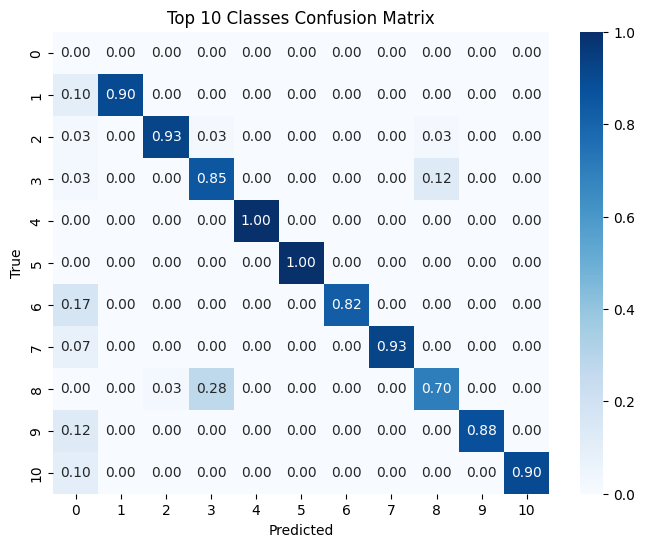

In [28]:
plt.figure(figsize=(8,6))

sns.heatmap(
    cm_10_norm,
    annot=True,
    cmap="Blues",
    fmt=".2f"
)

plt.title("Top 10 Classes Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")

plt.show()

In [29]:
sample_df = test_df
sample_df["actual"] = sample_df["label"]
sample_df["predicted"] = y_pred

In [30]:
label_map = (
    sample_df[["label", "label_text"]]
    .drop_duplicates()
    .set_index("label")["label_text"]
    .to_dict()
)

In [31]:
sample_df["actual_intent"] = sample_df["actual"].map(label_map)
sample_df["predicted_intent"] = sample_df["predicted"].map(label_map)

In [32]:
errors_df = sample_df[
    sample_df["actual"] != sample_df["predicted"]
]

errors_df = errors_df.sample(
    min(10, len(errors_df)),
    random_state=42
)

errors_df[
    [
        "text",
        "actual_intent",
        "predicted_intent"
    ]
]

,text,actual_intent,predicted_intent
433,Can I change my currency from USD to EUR?,exchange_via_app,fiat_currency_support
1798,The new card that was just sent to me was decl...,declined_card_payment,card_not_working
2208,Do charge fees for transfers?,transfer_fee_charged,top_up_by_bank_transfer_charge
1403,Freeze my account it's been hacked.,compromised_card,lost_or_stolen_phone
2923,how long and how much does it cost for new card,card_about_to_expire,order_physical_card
2571,Will there be additional costs of I make a wit...,wrong_exchange_rate_for_cash_withdrawal,cash_withdrawal_charge
2781,how much you charge for exhcange,exchange_charge,top_up_by_bank_transfer_charge
2296,What are your policies for card transfers?,failed_transfer,top_up_by_bank_transfer_charge
2742,How do I cancel my card? There are charges on ...,cash_withdrawal_not_recognised,compromised_card
2464,how come i can't find anywhere to load using cash,top_up_by_cash_or_cheque,declined_cash_withdrawal


In [33]:
results = trainer.evaluate()
results

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'eval_loss': 0.7009668946266174,
 'eval_accuracy': 0.912,
 'eval_f1_macro': 0.9098782622616468,
 'eval_runtime': 1.6949,
 'eval_samples_per_second': 590.021,
 'eval_steps_per_second': 18.881,
 'epoch': 8.0}

In [34]:
# predict intent

clf = pipeline(
    "text-classification",
    model=trainer.model,
    tokenizer=tokenizer
)

text = "my account is locked"
pred = clf(text)[0]

pred_id = int(pred["label"].split("_")[1])

print("Text:", text)
print("Prediction:", label_map[pred_id])
print("Confidence:", pred["score"])

Text: my account is locked
Prediction: terminate_account
Confidence: 0.198816180229187
